# Bonus - Part 1: Is the pretrained model really better? A deeper analysis
`Module_9_1.ipynb` (the graded deliverable) compares **one** run of a scratch CNN with **one** run of a pretrained VGG16.
Single runs are noisy, so this optional notebook repeats and extends that comparison on the **same limited dataset**
(150 / 50 / 100 train / validation / test images per class):

| Question | Experiment |
|---|---|
| Does data augmentation really help? | scratch CNN with vs. without `DataAug`, 3 seeds |
| How noisy is a single run? | every model is repeated with seeds 42, 43, 44 (mean +/- std) |
| How much does the training-set size matter? | 50, 100 and 150 training images per class |
| Is it better to fine-tune the last VGG16 block? | frozen base vs. fine-tuned `block5` |
| Is VGG16 special? | second pretrained backbone: ResNet50 |
| Where do the models fail? | confusion matrices, precision / recall / F1, most confident mistakes |

The experiments are implemented in `src/hw9/experiments.py` and take about 40 minutes on a CPU, so their results are cached in
`bonus_results/results.json`; this notebook loads the cache (and re-runs everything automatically if the cache is missing).

In [1]:
import sys, os, json
sys.path.insert(0, "src")                       # run this notebook from the repository root
import numpy as np, pandas as pd
from hw9 import experiments as X

RESULTS = "bonus_results/results.json"
if not os.path.exists(RESULTS):                 # first run on a new machine: compute everything (slow)
    from hw9.data import prepare_limited_dataset
    prepare_limited_dataset("limited_data", "data")
    X.run_all("limited_data", "bonus_results", "data")
R = json.load(open(RESULTS))
print("models:", list(R))
print("runs per (model, size):", {m: {n: len(v) for n, v in R[m].items()} for m in R})

I0000 00:00:1795078367.599836   17469 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795078367.640621   17469 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1795078368.854361   17469 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


models: ['vgg16_frozen', 'resnet50_frozen', 'vgg16_finetune', 'scratch_aug', 'scratch_noaug']
runs per (model, size): {'vgg16_frozen': {'50': 3, '100': 3, '150': 3}, 'resnet50_frozen': {'50': 3, '100': 3, '150': 3}, 'vgg16_finetune': {'150': 3}, 'scratch_aug': {'150': 3, '100': 3, '50': 3}, 'scratch_noaug': {'150': 3}}


## 1. Overview - all models, 300 training images (mean +/- std over 3 seeds)

In [2]:
pd.DataFrame(X.summary_table(R, 150)).set_index("model")

,runs,train acc,test acc,test F1
model,,,,
Scratch CNN (no augmentation),3,0.631,0.588 +/- 0.067,0.669
Scratch CNN (+ augmentation),3,0.733,0.675 +/- 0.025,0.686
VGG16 (frozen),3,1.000,0.948 +/- 0.008,0.948
VGG16 (fine-tuned block5),3,1.000,0.893 +/- 0.008,0.899
ResNet50 (frozen),3,0.999,0.963 +/- 0.009,0.964


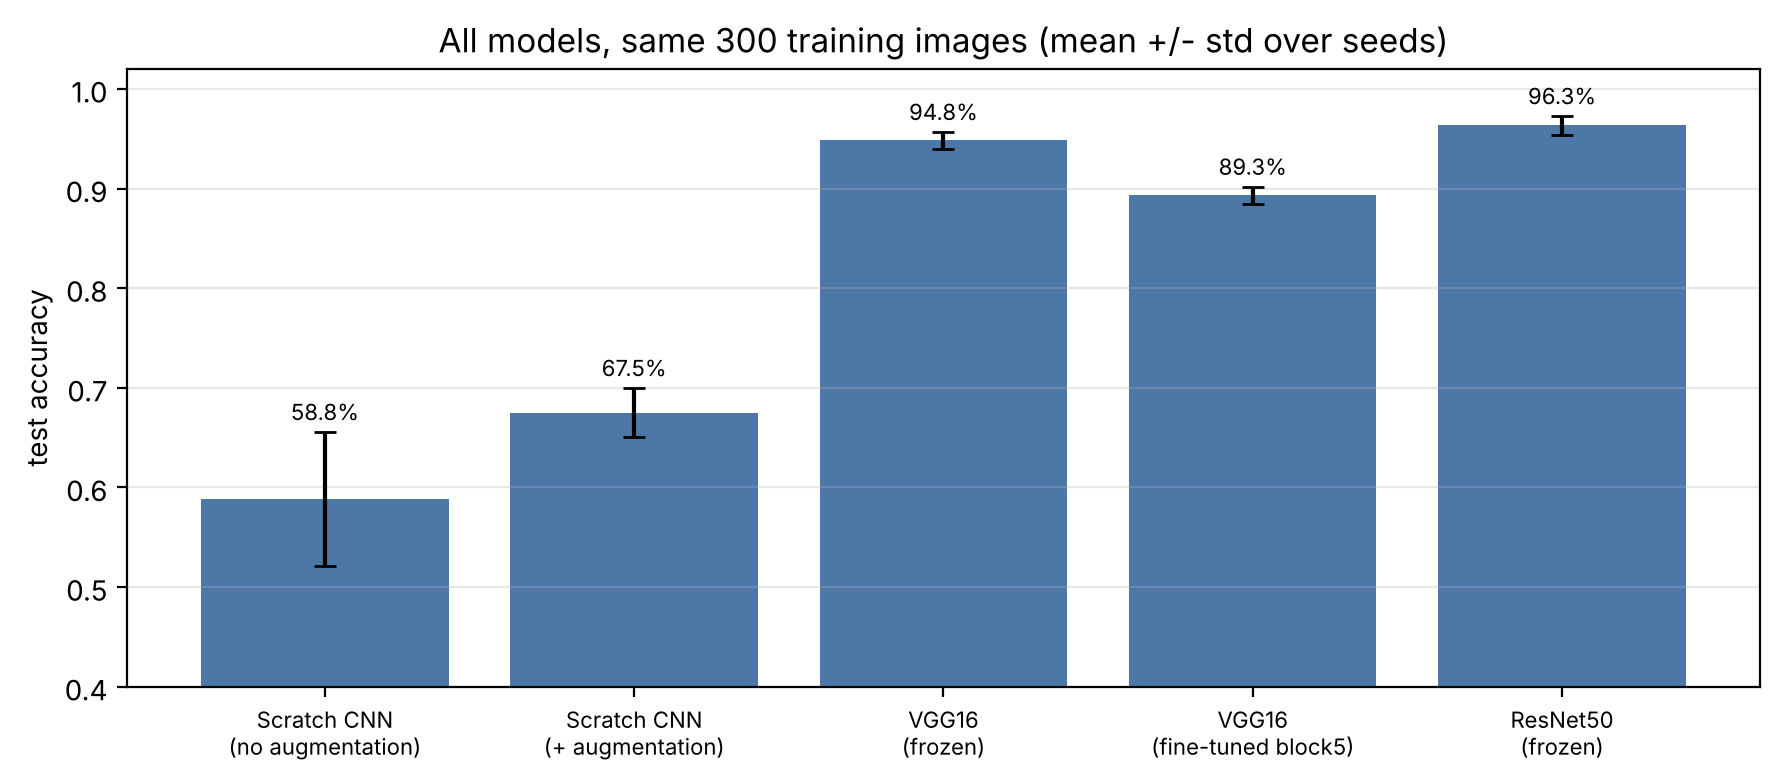

In [3]:
X.plot_final_comparison(R, 150)

In [4]:
# every individual run (test accuracy), so the spread is visible
rows = []
for m in ["scratch_noaug", "scratch_aug", "vgg16_frozen", "vgg16_finetune", "resnet50_frozen"]:
    rows.append({"model": X.LABELS[m].replace("\n", " "), **{f"seed {s}": f"{r['test']['accuracy']:.3f}" for s, r in R[m]["150"].items()}})
pd.DataFrame(rows).set_index("model")

,seed 42,seed 43,seed 44
model,,,
Scratch CNN (no augmentation),0.670,0.590,0.505
Scratch CNN (+ augmentation),0.690,0.695,0.640
VGG16 (frozen),0.960,0.940,0.945
VGG16 (fine-tuned block5),0.905,0.885,0.890
ResNet50 (frozen),0.950,0.970,0.970


## 2. Does data augmentation help the scratch CNN?

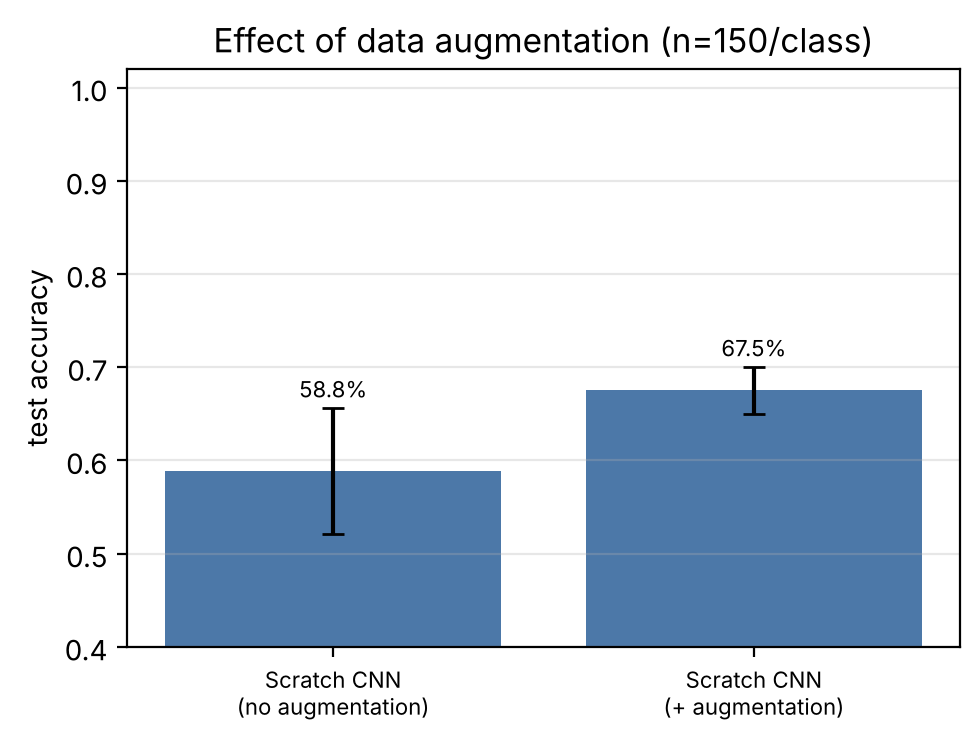

without augmentation: 58.8% +/- 6.7%   (seeds: [0.67, 0.59, 0.505])
with    augmentation: 67.5% +/- 2.5%   (seeds: [0.69, 0.695, 0.64])
-> augmentation changes test accuracy by +8.7 percentage points


In [5]:
X.plot_ablation(R, 150)
a, b = X.acc(R, "scratch_noaug", 150), X.acc(R, "scratch_aug", 150)
print(f"without augmentation: {a.mean():.1%} +/- {a.std():.1%}   (seeds: {np.round(a, 3).tolist()})")
print(f"with    augmentation: {b.mean():.1%} +/- {b.std():.1%}   (seeds: {np.round(b, 3).tolist()})")
print(f"-> augmentation changes test accuracy by {100 * (b.mean() - a.mean()):+.1f} percentage points")

**Finding.** Augmentation raised the scratch CNN's mean test accuracy by roughly **9 percentage points** and made the result much more stable
(std 6.7 -> 2.5 points). It is the right tool for a model that has to be trained from scratch, but with only 3 seeds the difference is
indicative rather than statistically conclusive, and even the augmented model is still far below any pretrained model.

## 3. How does accuracy depend on the number of training images?

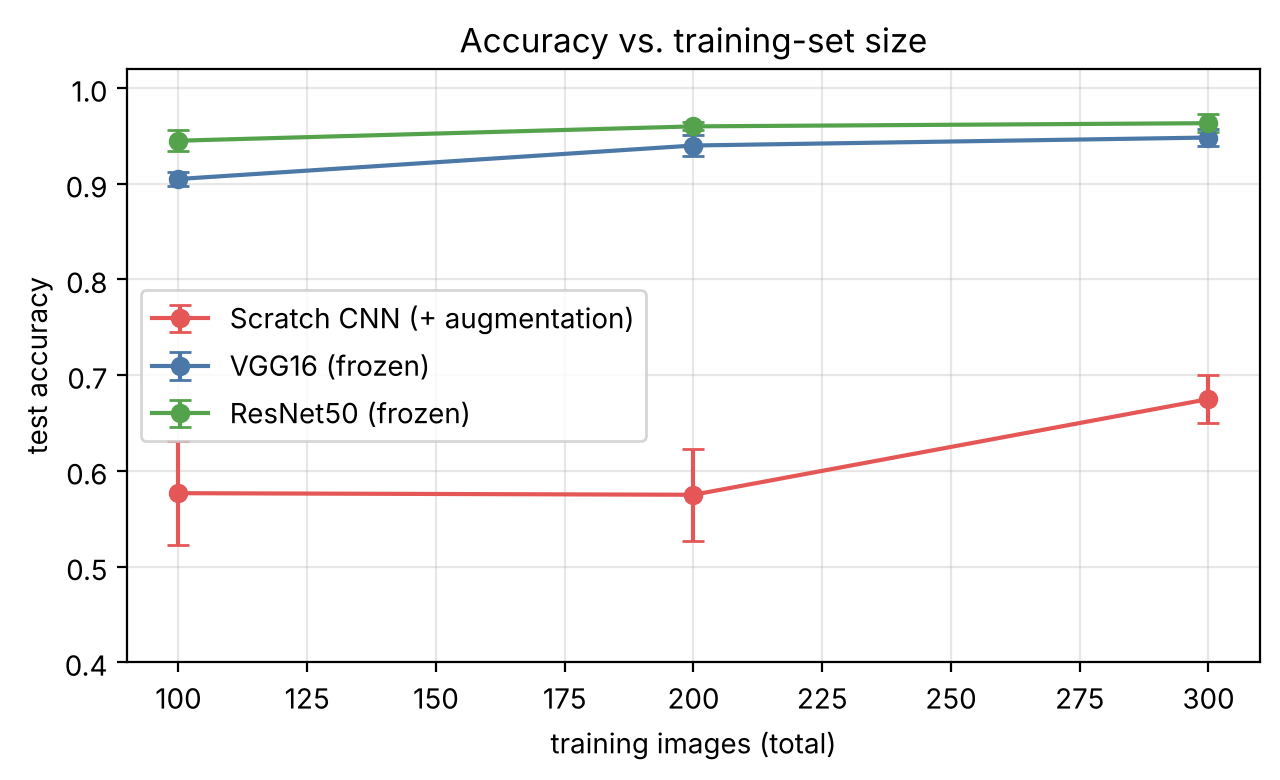

,100 images,200 images,300 images
model,,,
Scratch CNN (+ augmentation),0.577 +/- 0.054,0.575 +/- 0.048,0.675 +/- 0.025
VGG16 (frozen),0.905 +/- 0.007,0.940 +/- 0.011,0.948 +/- 0.008
ResNet50 (frozen),0.945 +/- 0.011,0.960 +/- 0.004,0.963 +/- 0.009


In [6]:
X.plot_size_sweep(R)
rows = []
for m in ["scratch_aug", "vgg16_frozen", "resnet50_frozen"]:
    rows.append({"model": X.LABELS[m].replace("\n", " "),
                 **{f"{2 * int(n)} images": f"{X.acc(R, m, n).mean():.3f} +/- {X.acc(R, m, n).std():.3f}" for n in sorted(R[m], key=int)}})
pd.DataFrame(rows).set_index("model")

**Finding.** The pretrained backbones are already at **~90-95 % with only 100 training images** and gain just a few points from 3x more data.
The scratch CNN stays around **58 %** (close to the 50 % of random guessing) until 300 images and only then starts to improve.
The less data, the bigger the advantage of transfer learning.

## 4. Fine-tuning and a second backbone

In [7]:
fz, ft, rs = (X.acc(R, m, 150) for m in ("vgg16_frozen", "vgg16_finetune", "resnet50_frozen"))
print(f"VGG16 frozen base          : {fz.mean():.1%} +/- {fz.std():.1%}")
print(f"VGG16 + fine-tuned block5  : {ft.mean():.1%} +/- {ft.std():.1%}   ({100 * (ft.mean() - fz.mean()):+.1f} points)")
print(f"ResNet50 frozen base       : {rs.mean():.1%} +/- {rs.std():.1%}   ({100 * (rs.mean() - fz.mean()):+.1f} points vs. VGG16)")
print("train accuracy of the fine-tuned model:", round(float(X.acc(R, 'vgg16_finetune', 150, 'train').mean()), 3))

VGG16 frozen base          : 94.8% +/- 0.8%
VGG16 + fine-tuned block5  : 89.3% +/- 0.8%   (-5.5 points)
ResNet50 frozen base       : 96.3% +/- 0.9%   (+1.5 points vs. VGG16)
train accuracy of the fine-tuned model: 1.0


**Findings.**
* **Fine-tuning did not help here - it hurt (about -5 points).** Unfreezing `block5` adds millions of trainable weights; with only 300 images the model reaches 100 % training accuracy and over-fits.
  With so little data, *frozen* features are the safer choice; fine-tuning usually needs more data and/or augmentation.
* **ResNet50 was the best backbone (about +1.5 points over VGG16)**, so the benefit of transfer learning is not specific to VGG16.

## 5. Error analysis (precision / recall: mean of 3 seeds; confusion matrices and mistakes: seed 42)

In [8]:
rows = []
for m in ["scratch_aug", "vgg16_frozen", "vgg16_finetune", "resnet50_frozen"]:
    t = [r["test_metrics"] for r in R[m]["150"].values()]
    rows.append({"model": X.LABELS[m].replace("\n", " "),
                 "precision (dog)": round(np.mean([x["precision"] for x in t]), 3),
                 "recall (dog)": round(np.mean([x["recall"] for x in t]), 3),
                 "F1": round(np.mean([x["f1"] for x in t]), 3)})
pd.DataFrame(rows).set_index("model")

,precision (dog),recall (dog),F1
model,,,
Scratch CNN (+ augmentation),0.666,0.710,0.686
VGG16 (frozen),0.944,0.953,0.948
VGG16 (fine-tuned block5),0.855,0.947,0.899
ResNet50 (frozen),0.951,0.977,0.964


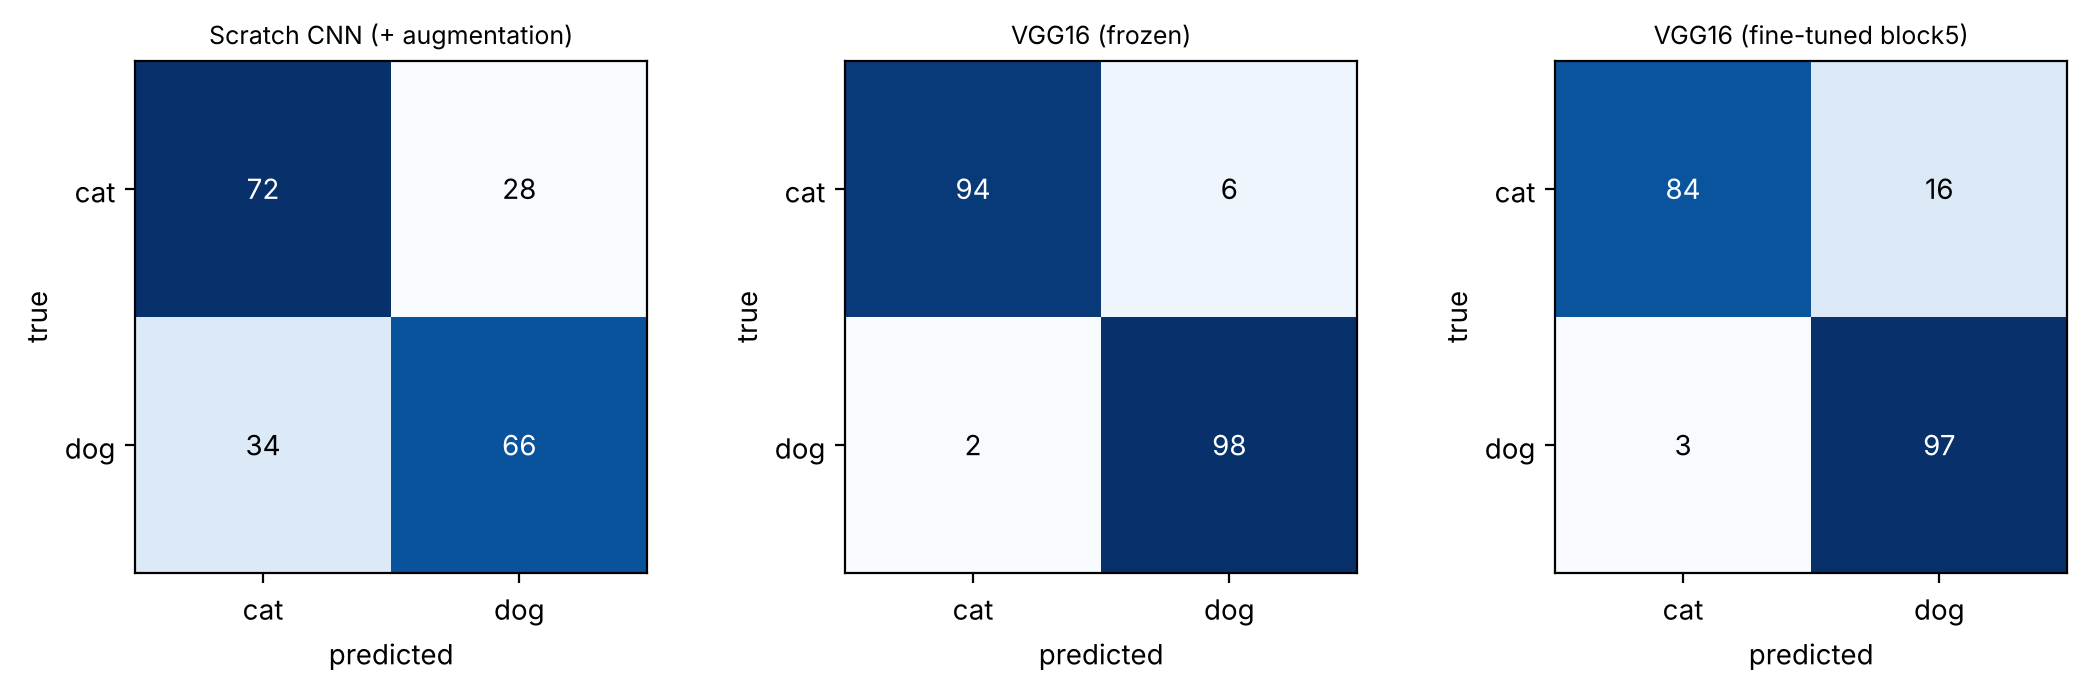

In [9]:
X.plot_confusions("bonus_results/test_predictions.npz")

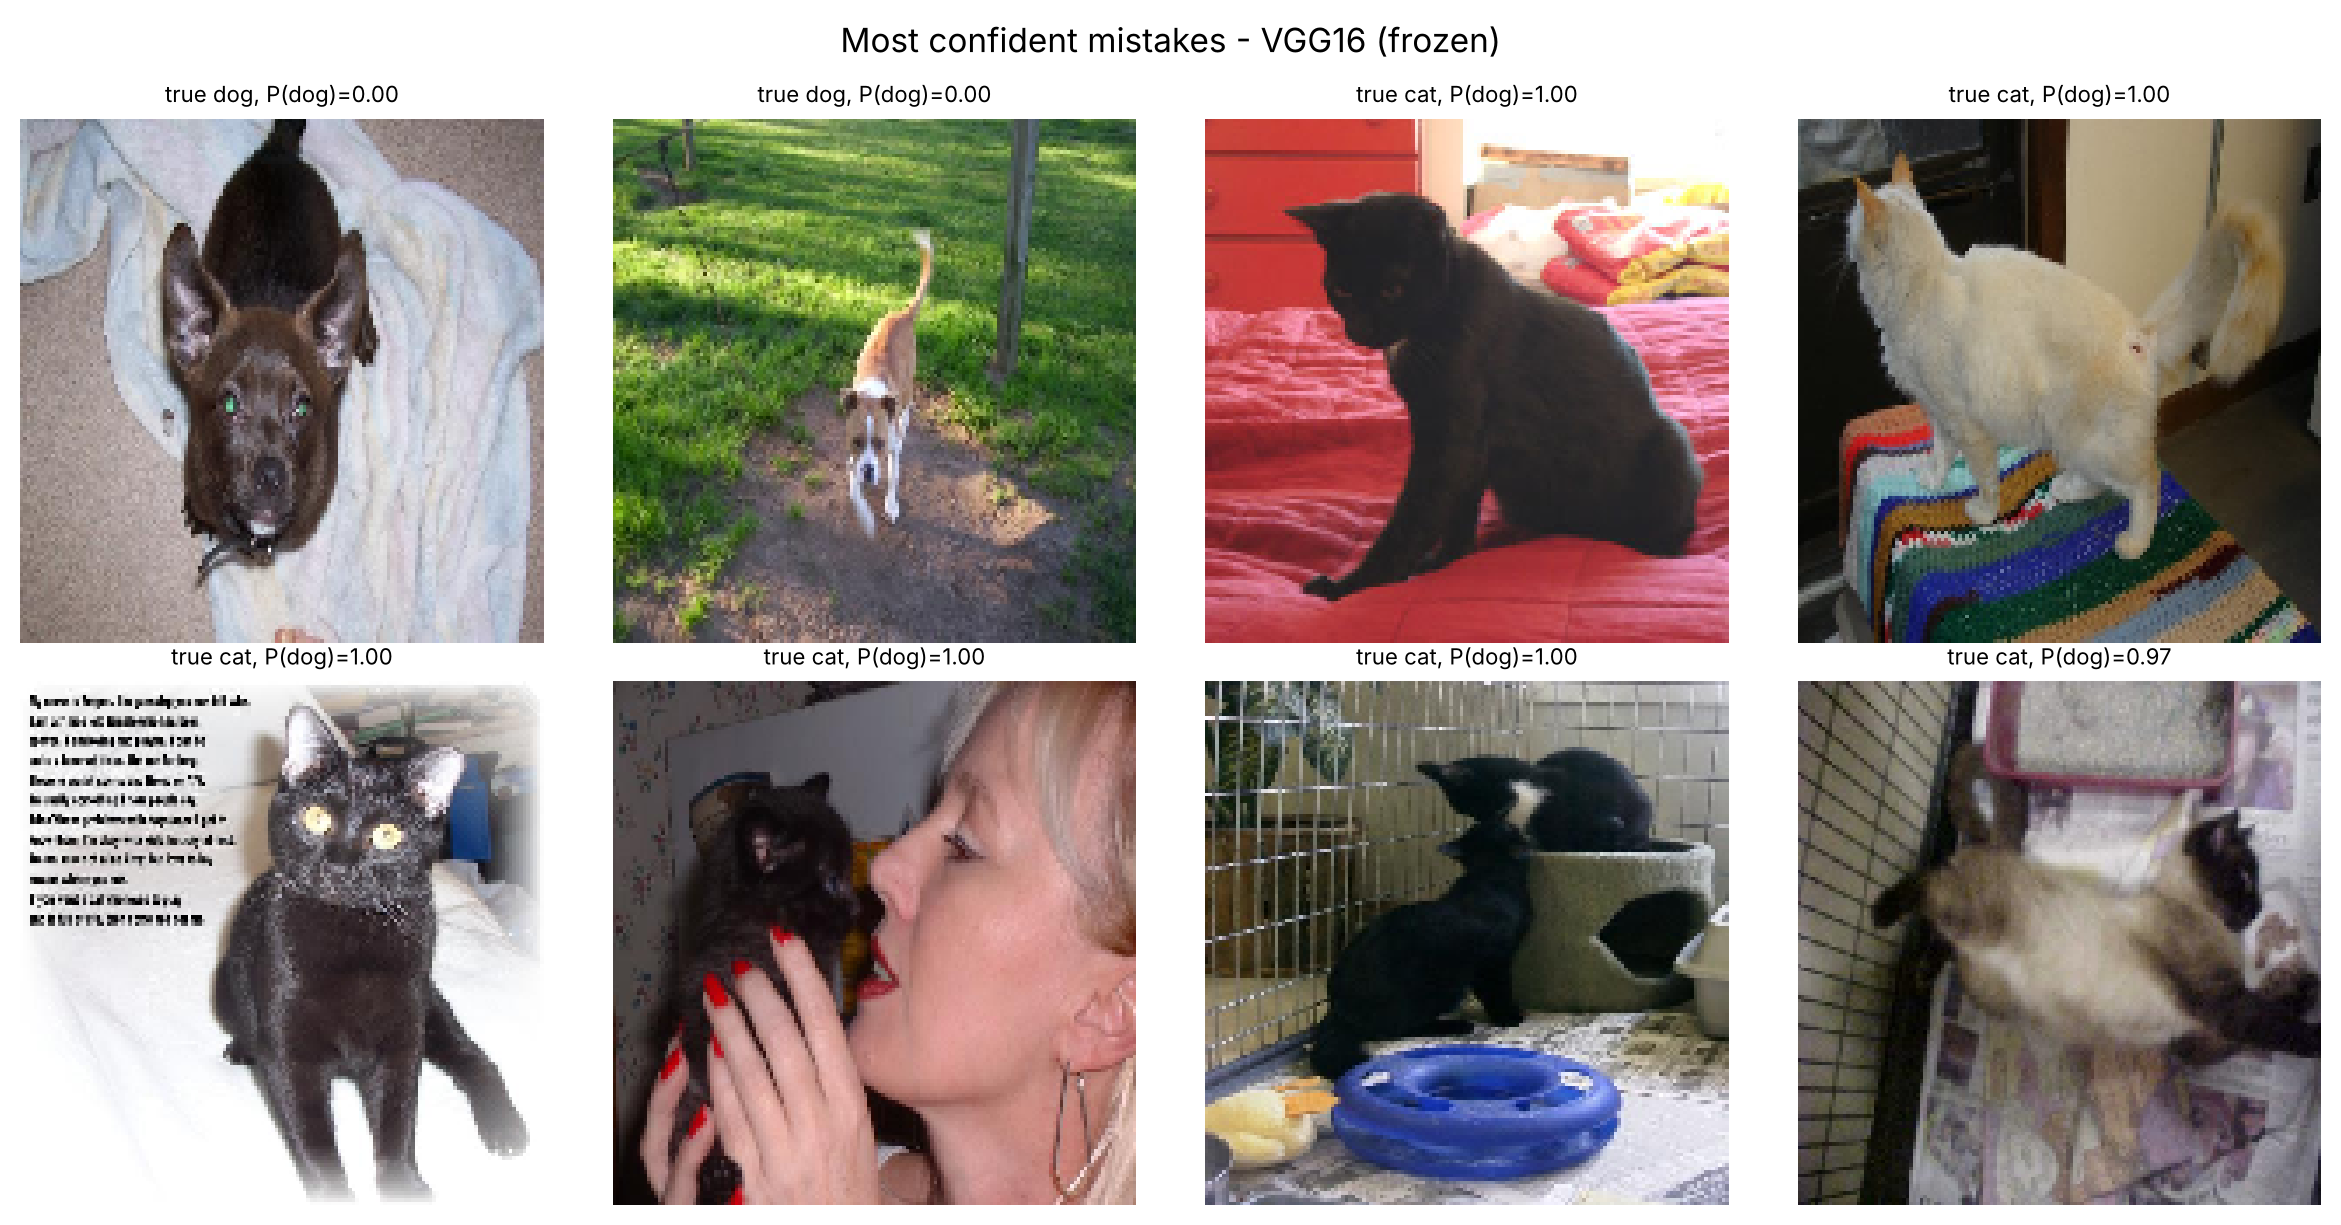

In [10]:
# the most confident mistakes of the frozen VGG16 (needs the images from ./limited_data)
if os.path.isdir("limited_data/test"):
    X.plot_misclassified("bonus_results/test_predictions.npz", "vgg16_frozen", k=8)
else:
    print("limited_data/ not found - run `python run_part1.py` once to create it")

**Findings.**
* The scratch CNN makes many errors in *both* directions (28 cats called dogs, 34 dogs called cats on 200 test images).
* Frozen VGG16 makes only 8 errors (6 cats called dogs, 2 dogs called cats); fine-tuning raised the cat -> dog errors to 16.
* Most of VGG16's confident mistakes are **dark / black cats** and **cluttered scenes** (a person holding the cat, cage bars, text on the photo) - cases where the animal is partly hidden or low-contrast.

## 6. Conclusions and caveats
1. **Transfer learning wins by a wide margin on tiny datasets** (about 95-96 % vs. 59-68 % at 300 images), and it is far more stable across seeds.
2. **Augmentation helps a scratch model** (about +9 points here) but cannot close the gap.
3. **Do not fine-tune blindly:** on 300 images, training only a small head on frozen features beat fine-tuning one VGG block.
4. **Caveats:** 3 seeds per setting; one specific limited dataset (300 training / 200 test images, so one image = 0.5 percentage points);
   learning rates and epochs were chosen once and not tuned per model; the "backup" cat/dog photos are a different (older) sample than the official `cats_and_dogs_filtered` set.